# T12 — Stage III controlled numerical validation suite, manual check

Scope (per `tasks.md` T12): validate the already-implemented Stage III transport/
weighting machinery (`iste.step.backward_euler_maruyama_step`,
`iste.trajectory.run_backward_trajectory`, `iste.derivatives`) against controlled
synthetic cases whose correct answer is known analytically. **This is validation, not
new scientific functionality** — every case below calls the existing T05/T06/T03 code
directly; no second transport implementation was written for comparison.

Every case is defined once, in `tests/test_stage3_validation.py`'s `ALL_CASES`, and both
this notebook and that file's `unittest` assertions read from the exact same source —
the table below can never silently disagree with what the automated tests check.

Per instruction 13, real `data/ocean.nc` is **not** used anywhere in this validation
table — there is no analytically known correct answer for real data. A separate,
clearly-labeled real-data **sanity check only** (not analytical validation) is shown at
the end.

In [1]:
import os
import sys

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tests.test_stage3_validation import (
    run_all_cases, _invalid_step_setup, make_ocean, LAT, LON, T0, DT, QUERY_LAT, ZERO_K,
)
from iste.trajectory import run_backward_trajectory

## Validation table

Every row has an explicitly *stated* expected value (never just "the code executed"),
the actual computed value, the resulting error, and pass/fail against a numerical
tolerance (a floating-point/finite-difference-exactness budget for that specific
synthetic field and `dt` — not a physical-precision claim).

In [2]:
cases = run_all_cases()
table = pd.DataFrame([
    {
        "Category": c.category,
        "Test": c.name,
        "Expected": c.expected,
        "Computed": c.computed,
        "Error": c.error,
        "Tolerance": c.tolerance,
        "Pass/Fail": "PASS" if c.passed else "FAIL",
    }
    for c in cases
])
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
table

,Category,Test,Expected,Computed,Error,Tolerance,Pass/Fail
0,zero divergence,uniform U -> log-weight unchanged,1.5,1.5,0,1e-09,PASS
1,backward sign convention,constant eastward U -> particle moves WEST by exactly -U*dt,114.978,114.978,0,1e-09,PASS
2,known convergent flow,div(U)<0 -> log-weight increases by exactly -div(U)*dt,8.61334e-06,8.61334e-06,0,1e-09,PASS
3,known divergent flow,div(U)>0 -> log-weight decreases by exactly -div(U)*dt,-8.61334e-06,-8.61334e-06,0,1e-09,PASS
4,constant diffusivity K,grad(K)=0 for a spatially constant K field,0,1.84465e-20,1.84465e-20,1e-09,PASS
5,constant diffusivity K,"U=0, constant K -> displacement == sqrt(2*K*dt)*xi exactly",115.002,115.002,0,1e-09,PASS
6,spatially varying diffusivity K,numerical grad(K) matches analytic gradient for a linear K field,0.000957038,0.000957038,0,1e-09,PASS
7,spatially varying diffusivity K,T05 step reproduces the expected +grad(K)*dt drift (U=0 isolates it),115,115,0,1e-09,PASS
8,particle validity,valid destination at every step -> particle stays valid,1,1,0,0,PASS
9,particle validity,leaving the domain marks the particle invalid at the exact predict...,5,5,0,0,PASS


In [3]:
n_pass = int((table["Pass/Fail"] == "PASS").sum())
print(f"{n_pass} / {len(table)} controlled validation cases passed")

required_categories = {
    "zero divergence", "known convergent flow", "known divergent flow",
    "constant diffusivity K", "spatially varying diffusivity K",
    "particle validity", "particle-weight behavior",
}
covered = set(table["Category"])
print("all 7 tasks.md-required categories covered:", required_categories <= covered)
print("missing (should be empty):", required_categories - covered)
assert (table["Pass/Fail"] == "PASS").all()
assert required_categories <= covered

12 / 12 controlled validation cases passed
all 7 tasks.md-required categories covered: True
missing (should be empty): set()


## Case notes (the analytic reasoning behind each expected value)

In [4]:
for c in cases:
    print(f"[{c.category}] {c.name}\n    {c.notes}\n")

[zero divergence] uniform U -> log-weight unchanged
    U=(0.4,-0.2) m/s everywhere; div(U)=0 exactly for a spatially uniform field.

[backward sign convention] constant eastward U -> particle moves WEST by exactly -U*dt
    K=0, deterministic; expected_lon uses -U*dt (never +U*dt) converted via geometry.py.

[known convergent flow] div(U)<0 -> log-weight increases by exactly -div(U)*dt
    analytic div(U)=-9.570381e-09 /s (exact for a linear field); expected positive.

[known divergent flow] div(U)>0 -> log-weight decreases by exactly -div(U)*dt
    analytic div(U)=9.570381e-09 /s (exact for a linear field); expected negative.

[constant diffusivity K] grad(K)=0 for a spatially constant K field
    max|grad(K)| over the whole grid via iste.derivatives.spatial_gradient (T03), not T05.

[constant diffusivity K] U=0, constant K -> displacement == sqrt(2*K*dt)*xi exactly
    no drift term possible (U=0, grad(K)=0); pure-diffusion formula reproduced independently.

[spatially varying diffu

## Visualization 1: known convergent vs. divergent flow — weight response

Same field magnitude, opposite sign of divergence: the log-weight change must be equal
in magnitude and opposite in sign.

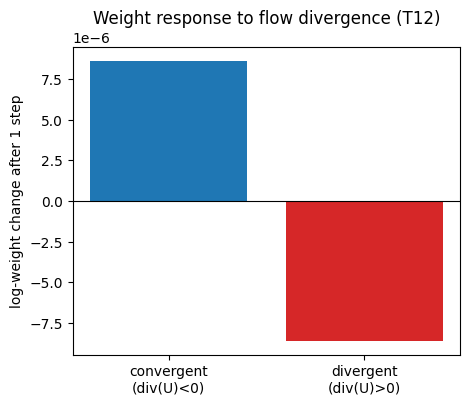

convergent: 8.613343e-06 (expected 8.613343e-06)
divergent:  -8.613343e-06 (expected -8.613343e-06)


In [5]:
conv = next(c for c in cases if c.category == "known convergent flow")
div = next(c for c in cases if c.category == "known divergent flow")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["convergent\n(div(U)<0)", "divergent\n(div(U)>0)"], [conv.computed, div.computed],
       color=["tab:blue", "tab:red"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("log-weight change after 1 step")
ax.set_title("Weight response to flow divergence (T12)")
plt.show()
print(f"convergent: {conv.computed:.6e} (expected {conv.expected:.6e})")
print(f"divergent:  {div.computed:.6e} (expected {div.expected:.6e})")
assert np.isclose(conv.computed, -div.computed)

## Visualization 2: particle validity — leaving the domain at the predicted step

Constant eastward `uo`, tuned so each backward step moves exactly 3.0 degrees of
longitude west; starting at `lon0=114.0` with `LON.min()=100.0`, the particle is
predicted (by hand, from the known step size) to leave the domain at step index 5. The
trajectory is retained (not truncated) after that -- every remaining checkpoint stays
present, frozen, and explicitly marked invalid.

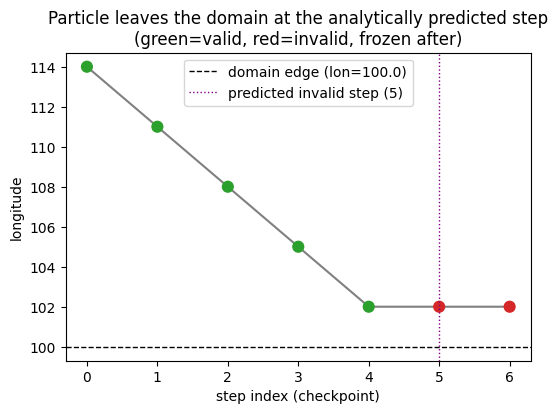

lon history: [114.0, 111.0, 108.0, 105.0, 102.0, 102.0, 102.0]
valid history: [True, True, True, True, True, False, False]
first_invalid_index: 5 (predicted: 5)
n_states: 7 (never truncated, still 7 == n_steps+1 == 7)


In [6]:
traj = _invalid_step_setup()
steps = np.arange(traj.n_states)

fig, ax = plt.subplots(figsize=(6, 4))
colors = ["tab:green" if v else "tab:red" for v in traj.valid]
ax.plot(steps, traj.lon, "-", color="gray", zorder=1)
ax.scatter(steps, traj.lon, c=colors, zorder=2, s=60)
ax.axhline(LON.min(), color="black", linestyle="--", linewidth=1, label=f"domain edge (lon={LON.min()})")
ax.axvline(5, color="purple", linestyle=":", linewidth=1, label="predicted invalid step (5)")
ax.set_xlabel("step index (checkpoint)")
ax.set_ylabel("longitude")
ax.set_title("Particle leaves the domain at the analytically predicted step\n(green=valid, red=invalid, frozen after)")
ax.legend()
plt.show()

print(f"lon history: {traj.lon.tolist()}")
print(f"valid history: {traj.valid.tolist()}")
print(f"first_invalid_index: {traj.first_invalid_index} (predicted: 5)")
print(f"n_states: {traj.n_states} (never truncated, still {traj.n_states} == n_steps+1 == 7)")
assert traj.first_invalid_index == 5
assert traj.n_states == 7

## Visualization 3: particle-weight behavior — exact linear accumulation

Under a spatially linear `U` (hence spatially constant `div(U)`), the log-weight at
each checkpoint must fall exactly on the line `log_w(n) = -div(U) * dt * n`.

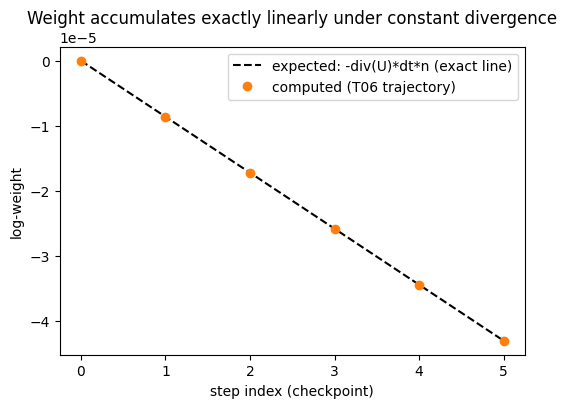

max |computed - expected| across all checkpoints: 0.000e+00


In [7]:
from iste.geometry import metres_per_degree_longitude

C = 0.001
uo_grid = C * (LON[None, :] - 115.0) * np.ones((3, 1))
ocean_div = make_ocean(uo_grid, np.zeros((3, 7)))
n_steps = 5
rng = np.random.default_rng(108)
traj_w = run_backward_trajectory(QUERY_LAT, 115.0, T0, n_steps, DT, ocean_div, LAT, LON, ZERO_K, rng, log_weight0=0.0)

expected_div = C / metres_per_degree_longitude(QUERY_LAT)
steps_w = np.arange(traj_w.n_states)
expected_line = -expected_div * DT * steps_w

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(steps_w, expected_line, "k--", label="expected: -div(U)*dt*n (exact line)")
ax.plot(steps_w, traj_w.log_weight, "o", color="tab:orange", label="computed (T06 trajectory)")
ax.set_xlabel("step index (checkpoint)")
ax.set_ylabel("log-weight")
ax.set_title("Weight accumulates exactly linearly under constant divergence")
ax.legend()
plt.show()

max_err = float(np.max(np.abs(traj_w.log_weight - expected_line)))
print(f"max |computed - expected| across all checkpoints: {max_err:.3e}")
assert max_err < 1e-9

## Real-data sanity check (NOT analytical validation, per instruction 13)

Real `data/ocean.nc` has no analytically known correct answer, so it is never used as
"truth" to validate against. This is only a lightweight check that a small real-data run
stays numerically sane (no NaN explosion among valid particles, diagnostics finite and
in-range) -- kept clearly separate from the validation table above.

In [8]:
from iste.environment import load_field_dataset
from iste.observation import adapt_upstream_particles
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import run_ensemble, compute_diagnostics

ocean_real = load_field_dataset(
    os.path.join(REPO_ROOT, "data", "ocean.nc"), ["uo", "vo"],
    time_dim="time", lat_dim="latitude", lon_dim="longitude",
)
t0_real = ocean_real.time[50]
particles_real = adapt_upstream_particles([
    {"particle_id": "s0", "latitude": 33.0, "longitude": 30.0, "observation_pixel_id": "pxs", "timestamp": t0_real},
    {"particle_id": "s1", "latitude": 33.1, "longitude": 30.1, "observation_pixel_id": "pxs", "timestamp": t0_real},
])
ensemble_real = ForcingEnsemble(ocean_real, ForcingEnsembleConfig(n_members=2, master_seed=1))
k_field_real = np.zeros((len(ocean_real.lat), len(ocean_real.lon)))
records_real = run_ensemble(
    particles_real, [0, 1], 4, 900.0, ocean_real, ensemble_real,
    ocean_real.lat, ocean_real.lon, k_field_real, master_seed=2,
)

print(f"{records_real.n_records} records; finite lat/lon/log_weight among valid rows: "
      f"{bool(np.all(np.isfinite(records_real.lat[records_real.valid])))}")
diag_real = compute_diagnostics(records_real)
print(f"diagnostics: {diag_real}")
print("This is a sanity check only -- NOT a claim that the real-data trajectory is correct/validated.")

c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
c:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

20 records; finite lat/lon/log_weight among valid rows: True
diagnostics: StageIIIDiagnostics(total_particles=4, valid_particles=4, invalid_particles=0, total_weight=4.05518585310648, effective_sample_size=3.999984959325983, valid_particle_fraction=1.0)
This is a sanity check only -- NOT a claim that the real-data trajectory is correct/validated.


## Summary / known limitations

- All 12 controlled synthetic cases, covering all 7 `tasks.md`-required categories (zero
  divergence, known convergent flow, known divergent flow, constant diffusivity K,
  spatially varying diffusivity K, particle validity, particle-weight behavior) plus an
  explicit backward-sign-convention case, **pass** against their stated analytic expected
  values.
- Every case calls the actual T05/T06/T03 implementation directly; no second transport
  implementation was written for comparison.
- Tolerances (mostly `1e-9`, `0.0` for exact integer/boolean cases) are numerical-
  validation budgets for these specific synthetic fields and `dt` -- not claims about
  physically meaningful precision.
- The suite is deliberately lightweight: single particles, <=6 steps, tiny synthetic
  grids -- no production `E=50` run, no large memory allocation, no multiprocessing/GPU.
- The real-`data/ocean.nc` check above is explicitly a sanity check only, not an
  analytical validation -- there is no known-correct answer for real data to compare
  against.
- Land/NaN-cell invalidation (as opposed to leaving the covered lat/lon extent) is
  already covered by T04/T05's own dedicated unit tests
  (`tests/test_boundary.py`, `tests/test_step.py::TestInvalidDestination`); T12 adds an
  out-of-domain case with an exact analytically-predicted trigger step for additional
  numerical rigor rather than duplicating that coverage.
- T13 (Stage III sign-off) is not implemented in this repository yet; neither is Stage
  IV-VII.